# Global Solution — CitizenTech
## Mobilidade Urbana Inteligente: Modelagem Matemática para a Gestão do Transporte Público

**FIAP · Modelagem Matemática e Computacional · Ciência da Computação**

| Integrante | RM |
|---|---|
| Arthur Primo Brandão | 573572 |
| Leandro Cavaccini Brito | 570556 |
| Lucas Dorice dos Santos | 568692 |

## Contextualização

A prefeitura contratou nossa equipe para tratar um desequilíbrio na frota de ônibus: algumas regiões têm ônibus de sobra enquanto outras não atendem a demanda. O registro de quantos ônibus cada centro operacional (Norte, Sul, Leste, Oeste) possui foi perdido, restando apenas indicadores consolidados.

Este notebook resolve o problema em duas etapas, usando **sistemas lineares, matrizes e transformações lineares** em Python:

1. **Etapa 1 — Diagnóstico:** recuperar a distribuição atual da frota a partir dos indicadores.
2. **Etapa 2 — Política de redistribuição:** propor e demonstrar matematicamente uma transformação linear que realoque os ônibus conforme a demanda.

**Conexão com o nosso projeto CitizenTech (Pulseira NFC Cidadã):** a pulseira permite validar a passagem por aproximação. Cada validação gera um dado de embarque por região e horário, o que substituiria pesquisas pontuais de demanda (como o Relatório II) por dados contínuos. O modelo deste notebook seria a camada de decisão que usa esses dados para redistribuir a frota, contribuindo para os **ODS 11** (cidades sustentáveis, transporte acessível), **ODS 10** (redução das desigualdades, ao priorizar regiões mal atendidas) e **ODS 9** (inovação aplicada a serviços públicos).

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

regioes = ["Norte", "Sul", "Leste", "Oeste"]

def mostrar_matriz(Mx, linhas, colunas, canto=""):
    # Imprime a matriz como tabela alinhada, com frações em uma única linha (ex.: 19/20)
    cel = [[str(Mx[i, j]) for j in range(Mx.cols)] for i in range(Mx.rows)]
    larg = max(len(c) for c in list(colunas) + [x for l in cel for x in l]) + 2
    lw = max(len(l) for l in list(linhas) + [canto]) + 2
    print(canto.ljust(lw) + "".join(c.rjust(larg) for c in colunas))
    print("-" * (lw + larg * len(colunas)))
    for nome, l in zip(linhas, cel):
        print(nome.ljust(lw) + "".join(x.rjust(larg) for x in l))

---
# ETAPA 1 — Diagnóstico e modelagem da situação atual

## 1a. Variáveis do problema

Sejam, respectivamente, as quantidades de ônibus alocados nos centros Norte, Sul, Leste e Oeste:

$$N,\; S,\; L,\; O \in \mathbb{N} = \{0, 1, 2, \dots\}$$

(inteiras e não negativas, conforme exige o enunciado). O vetor de estado é $\mathbf{x} = (N, S, L, O)^T$.

## 1b. Modelo matemático

Traduzindo cada indicador do Relatório I em uma equação:

**(E1)** Frota total de 72 ônibus:
$$N + S + L + O = 72$$

**(E2)** Norte + Oeste + dobro do Sul = 76:
$$N + 2S + O = 76$$

**(E3)** Sul + dobro do Leste = 52:
$$S + 2L = 52$$

**(E4)** Norte + Leste + dobro do Oeste = 76:
$$N + L + 2O = 76$$

Temos 4 equações lineares e 4 incógnitas.

## 1c. Representação matricial

O sistema é $A\mathbf{x} = \mathbf{b}$, com as colunas de $A$ na ordem $N, S, L, O$:

$$
\begin{pmatrix} 1 & 1 & 1 & 1 \\ 1 & 2 & 0 & 1 \\ 0 & 1 & 2 & 0 \\ 1 & 0 & 1 & 2 \end{pmatrix}
\begin{pmatrix} N \\ S \\ L \\ O \end{pmatrix}
=
\begin{pmatrix} 72 \\ 76 \\ 52 \\ 76 \end{pmatrix}
$$

em que a primeira matriz é $A$, o vetor de incógnitas é $\mathbf{x}$ e o vetor do lado direito é $\mathbf{b}$.

In [2]:
A = np.array([[1, 1, 1, 1],
              [1, 2, 0, 1],
              [0, 1, 2, 0],
              [1, 0, 1, 2]])
b = np.array([72, 76, 52, 76])

print("Matriz A:\n", A)
print("Vetor b:", b)

Matriz A:
 [[1 1 1 1]
 [1 2 0 1]
 [0 1 2 0]
 [1 0 1 2]]
Vetor b: [72 76 52 76]


## 1d. A distribuição é única? Investigação com Álgebra Linear

Dois critérios equivalentes aqui:

- **Teorema de Rouché–Capelli:** o sistema é possível se $\text{posto}(A) = \text{posto}([A \mid \mathbf{b}])$, e é *determinado* (solução única) se esse posto for igual ao número de incógnitas $n = 4$.
- **Determinante:** se $\det A \neq 0$, então $A$ é invertível e $\mathbf{x} = A^{-1}\mathbf{b}$ é a única solução.

Calculando o determinante por eliminação (subtraindo a linha 1 das linhas 2 e 4 e expandindo pela coluna de $N$):

$$
\det A = \det\begin{pmatrix} 1 & -1 & 0 \\ 1 & 2 & 0 \\ -1 & 0 & 1 \end{pmatrix}
= 1\cdot\big(1\cdot 2 - (-1)\cdot 1\big) = 3 \neq 0
$$

In [3]:
A_sp = sp.Matrix(A.tolist())
b_sp = sp.Matrix(b.tolist())
Ab_sp = A_sp.row_join(b_sp)

n_incognitas = A.shape[1]
print("det(A)          =", A_sp.det())
print("posto(A)        =", A_sp.rank())
print("posto([A | b])  =", Ab_sp.rank())
print("nº de incógnitas =", n_incognitas)

R, pivos = Ab_sp.rref()
print("\nForma escalonada reduzida de [A | b]:")
mostrar_matriz(R, ["linha 1", "linha 2", "linha 3", "linha 4"], ["N", "S", "L", "O", "b"])

unica = A_sp.det() != 0 and A_sp.rank() == Ab_sp.rank() == n_incognitas
print("\nSolução única?", unica)

det(A)          = 3
posto(A)        = 4
posto([A | b])  = 4
nº de incógnitas = 4

Forma escalonada reduzida de [A | b]:
            N   S   L   O   b
-----------------------------
linha 1     1   0   0   0  12
linha 2     0   1   0   0  20
linha 3     0   0   1   0  16
linha 4     0   0   0   1  24

Solução única? True


**Conclusão (1d):** $\det A = 3 \neq 0$ e $\text{posto}(A) = \text{posto}([A \mid \mathbf{b}]) = 4 = n$. Pelo Teorema de Rouché–Capelli o sistema é **possível e determinado (SPD)**: os indicadores preservados bastam para determinar **uma única** distribuição de veículos. A forma escalonada reduzida acima (matriz identidade à esquerda) já traz a solução na última coluna.

Resolução manual, para conferência:

1. $E_2 - E_1$: $S - L = 4 \Rightarrow S = L + 4$
2. Em $E_3$: $(L+4) + 2L = 52 \Rightarrow 3L = 48 \Rightarrow L = 16$ e $S = 20$
3. Em $E_1$: $N + O = 72 - 20 - 16 = 36$
4. Em $E_4$: $N + 16 + 2O = 76 \Rightarrow N + 2O = 60$; subtraindo $N + O = 36$: $O = 24$ e $N = 12$

## 1e. Resolução computacional

In [4]:
# Solução numérica (NumPy) e exata (SymPy)
x_num = np.linalg.solve(A, b)
x_exato = A_sp.LUsolve(b_sp)          # aritmética racional exata

atual = [int(v) for v in x_exato]     # [N, S, L, O]
print("Solução numérica :", x_num)
print("Solução exata    :", list(x_exato))
print()
print("Distribuição atual da frota")
print("---------------------------")
for r, q in zip(regioes, atual):
    print(f"{r:<6}: {q:>3} ônibus")
print(f"{'Total':<6}: {sum(atual):>3} ônibus")

Solução numérica : [12. 20. 16. 24.]
Solução exata    : [12, 20, 16, 24]

Distribuição atual da frota
---------------------------
Norte :  12 ônibus
Sul   :  20 ônibus
Leste :  16 ônibus
Oeste :  24 ônibus
Total :  72 ônibus


## 1f. Verificação com os registros operacionais

In [5]:
registros = [
    ("Frota total             N+S+L+O  ", [1, 1, 1, 1], 72),
    ("Norte+Oeste+2·Sul       N+2S+O   ", [1, 2, 0, 1], 76),
    ("Sul+2·Leste             S+2L     ", [0, 1, 2, 0], 52),
    ("Norte+Leste+2·Oeste     N+L+2O   ", [1, 0, 1, 2], 76),
]

todos_ok = True
for nome, coef, alvo in registros:
    valor = sum(c * q for c, q in zip(coef, atual))
    ok = valor == alvo
    todos_ok &= ok
    print(f"{nome} = {valor:>3} (esperado {alvo}) -> {'OK' if ok else 'ERRO'}")

print("\nValores inteiros e não negativos:", all(q >= 0 for q in atual))
print("Todos os registros satisfeitos  :", todos_ok)
assert todos_ok and np.allclose(A @ np.array(atual), b)

Frota total             N+S+L+O   =  72 (esperado 72) -> OK
Norte+Oeste+2·Sul       N+2S+O    =  76 (esperado 76) -> OK
Sul+2·Leste             S+2L      =  52 (esperado 52) -> OK
Norte+Leste+2·Oeste     N+L+2O    =  76 (esperado 76) -> OK

Valores inteiros e não negativos: True
Todos os registros satisfeitos  : True


---
# ETAPA 2 — Desenvolvimento de uma política de redistribuição

## 2a. Ônibus necessários por região

Como cada ônibus atende 40 passageiros e a quantidade de ônibus é inteira, o mínimo necessário em cada região é

$$n_i = \left\lceil \frac{\text{passageiros}_i}{40} \right\rceil$$

In [6]:
demanda = np.array([560, 760, 720, 840])
capacidade = 40

necessario = -(-demanda // capacidade)       # teto da divisão inteira
print(f"{'Região':<8}{'Demanda':>9}{'Necessários':>13}")
for r, d, n in zip(regioes, demanda, necessario):
    print(f"{r:<8}{d:>9}{n:>13}")
print(f"{'Total':<8}{demanda.sum():>9}{necessario.sum():>13}")
print("\nFrota disponível:", sum(atual), "| Necessário no total:", necessario.sum())

Região    Demanda  Necessários
Norte         560           14
Sul           760           19
Leste         720           18
Oeste         840           21
Total        2880           72

Frota disponível: 72 | Necessário no total: 72


O total necessário (72) é **exatamente igual** à frota disponível. Portanto, é possível atender 100% da demanda sem ampliar a frota, desde que ela seja bem distribuída.

## 2b. Desequilíbrios

Saldo = ônibus atuais − ônibus necessários (positivo = excedente, negativo = déficit).

In [7]:
atual_v = np.array(atual)
saldo = atual_v - necessario

print(f"{'Região':<8}{'Atual':>7}{'Necessário':>12}{'Saldo':>7}   Situação")
for r, a, n, s in zip(regioes, atual_v, necessario, saldo):
    sit = "excedente" if s > 0 else ("déficit" if s < 0 else "equilibrada")
    print(f"{r:<8}{a:>7}{n:>12}{s:>+7}   {sit}")

print("\nTotal de excedentes:", saldo[saldo > 0].sum())
print("Total de déficits  :", -saldo[saldo < 0].sum())

Região    Atual  Necessário  Saldo   Situação
Norte        12          14     -2   déficit
Sul          20          19     +1   excedente
Leste        16          18     -2   déficit
Oeste        24          21     +3   excedente

Total de excedentes: 4
Total de déficits  : 4


**Diagnóstico:** Sul tem 1 ônibus sobrando e Oeste tem 3 (4 ônibus excedentes no total). Norte e Leste têm déficit de 2 cada (4 ônibus faltando). Como excedentes e déficits são iguais, bastam **4 transferências**, o mínimo possível.

## 2c. Política de redistribuição e critérios

Critérios adotados:

1. **Preservar a frota total** (exigência da prefeitura): nenhum ônibus é criado ou removido.
2. **Só doam regiões com excedente** (Sul e Oeste). Regiões em déficit (Norte e Leste) ou equilibradas mantêm 100% dos seus ônibus.
3. **Só recebem regiões com déficit**, e exatamente o que falta, sem criar novo excedente.
4. **Movimentação mínima:** 4 ônibus movidos, igual ao total de excedentes.
5. **Resultado inteiro e não negativo**, pois ônibus são unidades indivisíveis.
6. **Doação concentrada na maior fonte:** o Oeste (maior excedente) envia 3; o Sul envia 1.

Plano de transferências (origem → destino):

| Origem | Destino | Ônibus |
|---|---|---|
| Oeste | Norte | 2 |
| Oeste | Leste | 1 |
| Sul | Leste | 1 |

Resultado esperado: Norte $12+2=14$, Sul $20-1=19$, Leste $16+1+1=18$, Oeste $24-3=21$. Todas as regiões passam a ter exatamente o necessário.

> Existem outras políticas válidas (por exemplo, o Oeste enviar 1 ao Norte e 2 ao Leste, com o Sul enviando 1 ao Norte). Escolhemos esta por usar poucas rotas e respeitar os critérios acima.

## 2d. A política como transformação linear

Definimos $T: \mathbb{R}^4 \to \mathbb{R}^4$ por

$$T(\mathbf{x}) = M\mathbf{x}, \qquad M = (m_{ij})_{4\times 4}$$

Toda aplicação da forma $\mathbf{x}\mapsto M\mathbf{x}$ é linear, pois $M(\alpha\mathbf{u}+\beta\mathbf{v}) = \alpha M\mathbf{u} + \beta M\mathbf{v}$. O vetor de entrada é a distribuição atual $\mathbf{x}=(N,S,L,O)^T$ e o de saída é a nova distribuição.

## 2e. Matriz da transformação e significado dos coeficientes

**Interpretação:** $m_{ij}$ é a **fração dos ônibus da região $j$ (coluna) que passa a operar na região $i$ (linha)**.

- Diagonal $m_{jj}$: fração que a região $j$ **mantém**.
- Fora da diagonal $m_{ij}$ ($i\neq j$): fração que a região $j$ **envia** à região $i$.

Cada coeficiente é calculado como (ônibus enviados de $j$ para $i$) ÷ (ônibus atuais de $j$), e a diagonal é o que sobra da coluna.

In [8]:
idx = {r: i for i, r in enumerate(regioes)}

# Plano de transferências: (origem, destino) -> nº de ônibus
envios = {("Oeste", "Norte"): 2,
          ("Oeste", "Leste"): 1,
          ("Sul",   "Leste"): 1}

# Consistência do plano com o diagnóstico (2b)
enviados  = {r: sum(q for (o, d), q in envios.items() if o == r) for r in regioes}
recebidos = {r: sum(q for (o, d), q in envios.items() if d == r) for r in regioes}
for r in regioes:
    assert enviados[r] - recebidos[r] == saldo[idx[r]], f"Plano inconsistente em {r}"

# Construção de M com frações exatas
M = sp.zeros(4, 4)
for (orig, dest), q in envios.items():
    M[idx[dest], idx[orig]] = sp.Rational(q, atual[idx[orig]])
for j in range(4):
    M[j, j] = 1 - sum(M[i, j] for i in range(4) if i != j)

print("Matriz M  (coluna = região de origem, linha = região de destino)\n")
mostrar_matriz(M, regioes, regioes, canto="destino \\ origem")

print("\nInterpretação dos coeficientes não triviais:")
for i in range(4):
    for j in range(4):
        if M[i, j] != 0 and M[i, j] != 1:
            if i == j:
                print(f"  m[{regioes[i]},{regioes[j]}] = {M[i,j]}: {regioes[j]} mantém {float(M[i,j]):.1%} dos seus ônibus")
            else:
                print(f"  m[{regioes[i]},{regioes[j]}] = {M[i,j]}: {regioes[j]} envia {float(M[i,j]):.1%} dos seus ônibus para {regioes[i]}")

Matriz M  (coluna = região de origem, linha = região de destino)

destino \ origem    Norte    Sul  Leste  Oeste
----------------------------------------------
Norte                   1      0      0   1/12
Sul                     0  19/20      0      0
Leste                   0   1/20      1   1/24
Oeste                   0      0      0    7/8

Interpretação dos coeficientes não triviais:
  m[Norte,Oeste] = 1/12: Oeste envia 8.3% dos seus ônibus para Norte
  m[Sul,Sul] = 19/20: Sul mantém 95.0% dos seus ônibus
  m[Leste,Sul] = 1/20: Sul envia 5.0% dos seus ônibus para Leste
  m[Leste,Oeste] = 1/24: Oeste envia 4.2% dos seus ônibus para Leste
  m[Oeste,Oeste] = 7/8: Oeste mantém 87.5% dos seus ônibus


Escrita explicitamente, e aplicada à distribuição atual:

$$
\begin{pmatrix} N' \\ S' \\ L' \\ O' \end{pmatrix} =
\begin{pmatrix}
1 & 0 & 0 & \frac{1}{12} \\
0 & \frac{19}{20} & 0 & 0 \\
0 & \frac{1}{20} & 1 & \frac{1}{24} \\
0 & 0 & 0 & \frac{7}{8}
\end{pmatrix}
\begin{pmatrix} 12 \\ 20 \\ 16 \\ 24 \end{pmatrix}
=
\begin{pmatrix} 14 \\ 19 \\ 18 \\ 21 \end{pmatrix}
$$

Leitura por colunas: **Norte** e **Leste** (colunas 1 e 3) são colunas da identidade, ou seja, não enviam ônibus. **Sul** (coluna 2) mantém $\frac{19}{20}$ e envia $\frac{1}{20}$ ao Leste. **Oeste** (coluna 4) envia $\frac{1}{12}$ ao Norte, $\frac{1}{24}$ ao Leste e mantém $\frac{7}{8}$.

## 2f. Demonstração: a transformação preserva o total e não gera alocações negativas

**(i) Preservação do total.** Seja $\mathbf{1}^T = (1,1,1,1)$. A soma das entradas de $\mathbf{x}$ é $\mathbf{1}^T\mathbf{x}$. Então

$$\mathbf{1}^T(M\mathbf{x}) = (\mathbf{1}^TM)\mathbf{x}$$

Cada coluna de $M$ soma 1 (o que a região $j$ mantém mais o que envia é 100% dos seus ônibus), logo $\mathbf{1}^TM = \mathbf{1}^T$ e

$$\mathbf{1}^T(M\mathbf{x}) = \mathbf{1}^T\mathbf{x} \quad \text{para todo } \mathbf{x}.$$

Para nossa frota: $14+19+18+21 = 72 = 12+20+16+24$.

**(ii) Não negatividade.** Todos os coeficientes satisfazem $m_{ij} \ge 0$. Se $x_j \ge 0$ para todo $j$, então cada saída $x'_i = \sum_j m_{ij}x_j$ é soma de produtos de números não negativos, portanto $x'_i \ge 0$.

**(iii) Inteiros.** Para a distribuição atual, $M\mathbf{x}$ resulta em inteiros (verificado abaixo), como exigido.

Verificação computacional:

In [9]:
x0 = sp.Matrix(atual)
x_novo = M * x0

# (i) cada coluna soma 1  =>  1ᵀM = 1ᵀ
somas_colunas = sp.ones(1, 4) * M
print("Soma de cada coluna de M:", list(somas_colunas))
assert all(s == 1 for s in somas_colunas)

# (ii) todos os coeficientes >= 0
assert all(c >= 0 for c in M)
print("Todos os coeficientes de M são >= 0: True")

# Resultado da política
print("\nNova distribuição T(x) = M·x")
for r, antes, depois, nec in zip(regioes, atual, x_novo, necessario):
    print(f"{r:<6}: {antes:>3} -> {int(depois):>3}  (necessário: {nec})")
print("Total antes:", sum(atual), "| Total depois:", sum(x_novo))

assert sum(x_novo) == sum(atual)
assert all(v >= 0 and v == int(v) for v in x_novo)
assert [int(v) for v in x_novo] == list(necessario)

# Testes numéricos extras: linearidade, conservação do total e não negatividade
rng = np.random.default_rng(42)
Mn = np.array(M.tolist(), dtype=float)
for _ in range(1000):
    u, v = rng.uniform(0, 100, 4), rng.uniform(0, 100, 4)
    alfa, beta = rng.uniform(-5, 5, 2)
    assert np.allclose(Mn @ (alfa*u + beta*v), alfa*(Mn @ u) + beta*(Mn @ v))   # linearidade
    assert np.isclose((Mn @ u).sum(), u.sum())                                 # total preservado
    assert (Mn @ u >= 0).all()                                                  # sem negativos
print("\n1000 testes aleatórios: linearidade, total e não negatividade confirmados.")

Soma de cada coluna de M: [1, 1, 1, 1]
Todos os coeficientes de M são >= 0: True

Nova distribuição T(x) = M·x
Norte :  12 ->  14  (necessário: 14)
Sul   :  20 ->  19  (necessário: 19)
Leste :  16 ->  18  (necessário: 18)
Oeste :  24 ->  21  (necessário: 21)
Total antes: 72 | Total depois: 72

1000 testes aleatórios: linearidade, total e não negatividade confirmados.


---
# Avaliação do resultado da intervenção

Comparamos a capacidade de atendimento antes e depois da política (capacidade = ônibus × 40).

Região    Demanda  Cap. antes  Não atend.  Cap. depois  Não atend.
Norte         560         480          80          560           0
Sul           760         800           0          760           0
Leste         720         640          80          720           0
Oeste         840         960           0          840           0

Demanda total atendida ANTES : 2720/2880 (94.4%)
Demanda total atendida DEPOIS: 2880/2880 (100.0%)
Passageiros sem vaga: 160 -> 0


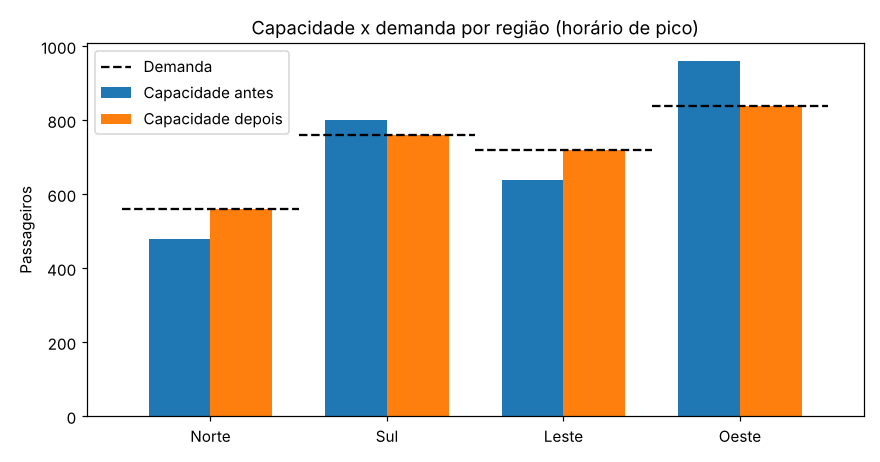

In [10]:
x_depois = np.array([int(v) for v in x_novo])
cap_antes  = atual_v * capacidade
cap_depois = x_depois * capacidade

atend_antes  = np.minimum(demanda, cap_antes)
atend_depois = np.minimum(demanda, cap_depois)

print(f"{'Região':<8}{'Demanda':>9}{'Cap. antes':>12}{'Não atend.':>12}{'Cap. depois':>13}{'Não atend.':>12}")
for i, r in enumerate(regioes):
    print(f"{r:<8}{demanda[i]:>9}{cap_antes[i]:>12}{demanda[i]-atend_antes[i]:>12}"
          f"{cap_depois[i]:>13}{demanda[i]-atend_depois[i]:>12}")

tot = demanda.sum()
print(f"\nDemanda total atendida ANTES : {atend_antes.sum()}/{tot} ({atend_antes.sum()/tot:.1%})")
print(f"Demanda total atendida DEPOIS: {atend_depois.sum()}/{tot} ({atend_depois.sum()/tot:.1%})")
print(f"Passageiros sem vaga: {tot-atend_antes.sum()} -> {tot-atend_depois.sum()}")

# Gráfico
x = np.arange(4); w = 0.35
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - w/2, cap_antes,  w, label="Capacidade antes")
ax.bar(x + w/2, cap_depois, w, label="Capacidade depois")
for i in range(4):
    ax.hlines(demanda[i], i - 0.5, i + 0.5, colors="black", linestyles="--",
              label="Demanda" if i == 0 else None)
ax.set_xticks(x); ax.set_xticklabels(regioes)
ax.set_ylabel("Passageiros"); ax.set_title("Capacidade x demanda por região (horário de pico)")
ax.legend(); plt.tight_layout(); plt.show()

## Conclusões

- **Etapa 1:** o sistema $A\mathbf{x}=\mathbf{b}$ tem $\det A = 3 \neq 0$, logo a distribuição é única: **Norte 12, Sul 20, Leste 16, Oeste 24**, e todos os registros do Relatório I são satisfeitos.
- **Etapa 2:** a demanda exige 14, 19, 18 e 21 ônibus, totalizando exatamente os 72 disponíveis. A política move apenas **4 ônibus** (Oeste→Norte: 2, Oeste→Leste: 1, Sul→Leste: 1) e é representada pela matriz $M$, cujas colunas somam 1 (total preservado) e cujos coeficientes são não negativos (sem alocações negativas).
- **Resultado:** a demanda atendida no pico passa de 94,4% (2720 de 2880) para 100%, eliminando os 160 passageiros sem vaga.

**Limitações assumidas** (o enunciado trata os dados como hipotéticos e simplificados):

- $M$ foi calibrada para a distribuição atual. Aplicada a outra distribuição ela continua preservando o total e sem gerar negativos, mas pode produzir valores fracionários, que na operação real exigiriam arredondamento.
- O modelo considera um único horário de pico e que cada ônibus atende apenas a região onde está alocado, simplificações previstas no enunciado.